# 03a — Cohort retention (company-grain, paid)

Builds the per-(cohort, month_offset) retention table from
`../sql/03a_cohort_retention.sql`, pivots it, and renders the heatmap to
`../figures/cohort_heatmap.png`.

**Run:** `export SAAS_DSN='<read-only postgres DSN>'` (never commit the DSN),
then run all cells. Definitions: M2 brief — active = `status='active'`;
cohort = month of first paid, non-trialing subscription (see SQL header for
why account `signup_date` is not the anchor).

In [1]:
import os
import re

import matplotlib.pyplot as plt
import pandas as pd
import psycopg2
import seaborn as sns

dsn = os.environ.get("SAAS_DSN")
assert dsn, "Set SAAS_DSN to the read-only Postgres DSN before running."
REPO = os.path.abspath(os.path.join(os.getcwd(), ".."))

In [2]:
with open(os.path.join(REPO, "sql", "03a_cohort_retention.sql")) as f:
    sql_text = f.read()
tail = sql_text.split("-- HEATMAP_QUERY", 1)[1]
code = "\n".join(
    ln for ln in tail.splitlines() if not ln.strip().startswith("--")
)
stmts = [s.strip() for s in re.split(r";\s*", code) if s.strip()]
heatmap_sql = stmts[-1]  # Q3 percentages query

conn = psycopg2.connect(dsn)
df = pd.read_sql(heatmap_sql, conn)
conn.close()
df["cohort"] = pd.to_datetime(df["cohort"])
print(df.shape)
df.head()

/tmp/ipykernel_1516161/1046521582.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(heatmap_sql, conn)


(586, 5)


,cohort,month_offset,cohort_size,n_active,retention_frac
0,2022-03-01,0,1,NaN,1.0
1,2022-03-01,1,1,0.0,0.0
2,2022-03-01,2,1,0.0,0.0
3,2022-03-01,3,1,0.0,0.0
4,2022-03-01,4,1,0.0,0.0


In [3]:
# Quality gates: month-0 is exactly 100%, nothing exceeds 100%
m0 = df[df.month_offset == 0].retention_frac
assert (m0 == 1.0).all(), "month-0 must be 100% for every cohort"
assert (df.retention_frac.dropna() <= 1.0).all(), "no cell may exceed 100%"

# Display range: readable cohorts (2024-01 onward); drop the partial 2026-06
# cohort (n=4, June extract incomplete)
piv = (
    df.assign(pct=100 * df.retention_frac)
    .pivot(index="cohort", columns="month_offset", values="pct")
)
sizes = df.groupby("cohort").cohort_size.first()
piv = piv.loc[(piv.index >= pd.Timestamp("2024-01-01")) & (piv.index <= pd.Timestamp("2026-05-01"))]
print("rows:", piv.shape[0], "cohort size range:",
      sizes.loc[piv.index].min(), "-", sizes.loc[piv.index].max())
piv.iloc[:, :6].round(0)

rows: 29 cohort size range: 10 - 48


month_offset,0,1,2,3,4,5
cohort,,,,,,
2024-01-01,100.0,70.0,70.0,70.0,70.0,70.0
2024-02-01,100.0,79.0,79.0,79.0,79.0,79.0
2024-03-01,100.0,67.0,67.0,67.0,67.0,67.0
2024-04-01,100.0,73.0,73.0,73.0,73.0,73.0
2024-05-01,100.0,60.0,60.0,60.0,60.0,60.0
2024-06-01,100.0,57.0,57.0,57.0,57.0,57.0
2024-07-01,100.0,71.0,71.0,71.0,71.0,71.0
2024-08-01,100.0,48.0,52.0,56.0,60.0,60.0
2024-09-01,100.0,76.0,76.0,81.0,81.0,81.0


saved: /home/anuj/Personal/Saas-CHurn-Akshobya\]/figures/cohort_heatmap.png


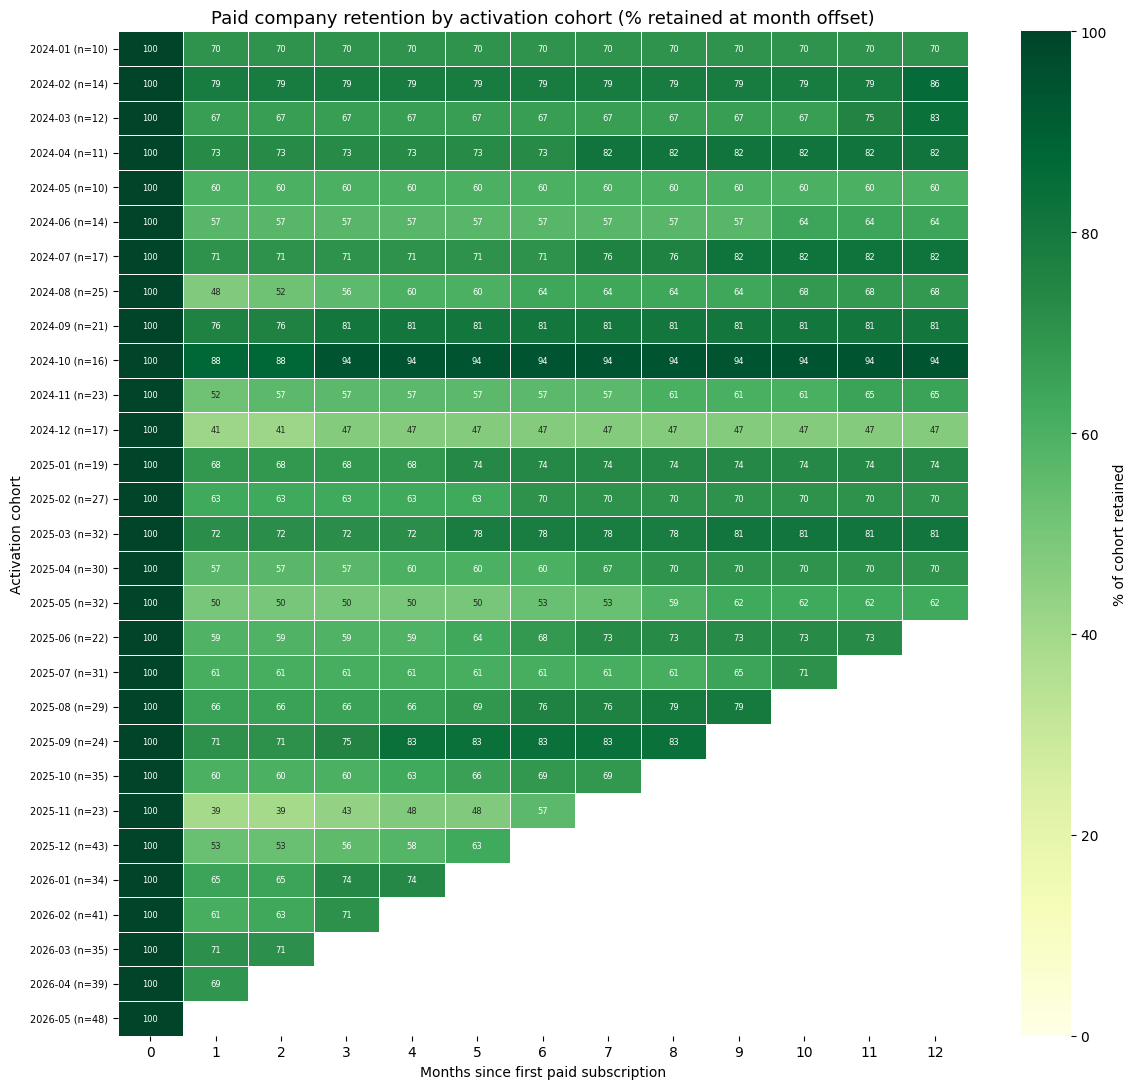

In [4]:
labels = [f"{c.strftime('%Y-%m')} (n={sizes[c]})" for c in piv.index]

plt.figure(figsize=(12, 11))
ax = sns.heatmap(
    piv,
    cmap="YlGn", vmin=0, vmax=100,
    annot=True, fmt=".0f", annot_kws={"fontsize": 6},
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "% of cohort retained"},
    mask=piv.isna(),
)
ax.set_title("Paid company retention by activation cohort (% retained at month offset)", fontsize=13)
ax.set_xlabel("Months since first paid subscription")
ax.set_ylabel("Activation cohort")
ax.set_yticklabels(labels, rotation=0, fontsize=7)
plt.tight_layout()
out = os.path.join(REPO, "figures", "cohort_heatmap.png")
plt.savefig(out, dpi=150)
print("saved:", out)

In [5]:
m1 = df[df.month_offset == 1].retention_frac
print(f"month-1 retention: mean={m1.mean():.1%}, range={m1.min():.0%}-{m1.max():.0%}")
late = df[df.month_offset >= 6].groupby("month_offset").retention_frac.mean()
print("mean retention by late offset:")
print((100 * late).round(1))
old = df[(df.cohort < "2025-01-01") & (df.month_offset == 12)].retention_frac.mean()
new = df[(df.cohort >= "2025-01-01") & (df.month_offset == 3)].retention_frac.mean()
print(f"2024 cohorts @month-12: {old:.0%} | 2025 cohorts @month-3: {new:.0%}")

month-1 retention: mean=63.6%, range=0%-100%
mean retention by late offset:
month_offset
6     69.4
7     70.3
8     70.8
9     71.3
10    71.6
11    72.6
12    73.0
Name: retention_frac, dtype: float64
2024 cohorts @month-12: 73% | 2025 cohorts @month-3: 62%
